# 30DayMapChallenge – Day 5: Senses | Sight 👁️

Can you see Vienna’s St. Stephen’s Cathedral from where you stand?

For Day 5, I explored the city through the sense of sight, using a viewshed analysis to identify locations in Vienna’s historic first district from which the iconic St. Stephen’s Cathedral (Stephansdom) is visible.

🟢 Green dots represent locations from which the cathedral is visible, with an unobstructed line of sight.

🔴 Red dots indicate locations where the view is blocked by buildings or other obstacles in the urban landscape.

Using a 1-metre resolution Digital Surface Model (DSM) and Digital Terrain Model (DTM), the analysis reveals how Vienna’s dense urban fabric shapes what we can and cannot see. The result is a visual exploration of visibility, perspective, and the relationship between the built environment and one of Vienna’s most recognisable landmarks.

#30DayMapChallenge #Day5 #Senses #Sight #Viewshed #Vienna #Stephansdom #GIS #SpatialAnalysis #Python #Cartography

#30DayMapChallenge #Day5 #Sight #GIS #Python #Viewshed #Vienna #Geospatial #SpatialAnalysis


Prerequesites:
- run `python 2026/05_sight.py`

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt

In [3]:
gdf = gpd.read_file("data/stephansdom_visibility.gpkg")
district = gpd.read_file("data/innere_stadt.geojson")
dom = gpd.read_file("data/stephansdom.geojson")

district = district.to_crs(gdf.crs)
dom = dom.to_crs(gdf.crs)

bbox = district.to_crs("EPSG:4326").total_bounds

wfs_url = (
    "https://data.wien.gv.at/daten/geo?"
    "service=WFS&"
    "version=2.0.0&"
    "request=GetFeature&"
    "typeNames=ogdwien:FMZKGEBOGD&"
    f"bbox={','.join([str(x) for x in bbox])},EPSG:4326&"
    "srsName=EPSG:31256"
)

gdf_buildings = gpd.read_file(wfs_url)
gdf_buildings.set_crs("EPSG:31256", inplace=True)
gdf_buildings = gdf_buildings.to_crs(gdf.crs)
gdf_buildings = gpd.clip(gdf_buildings, district)

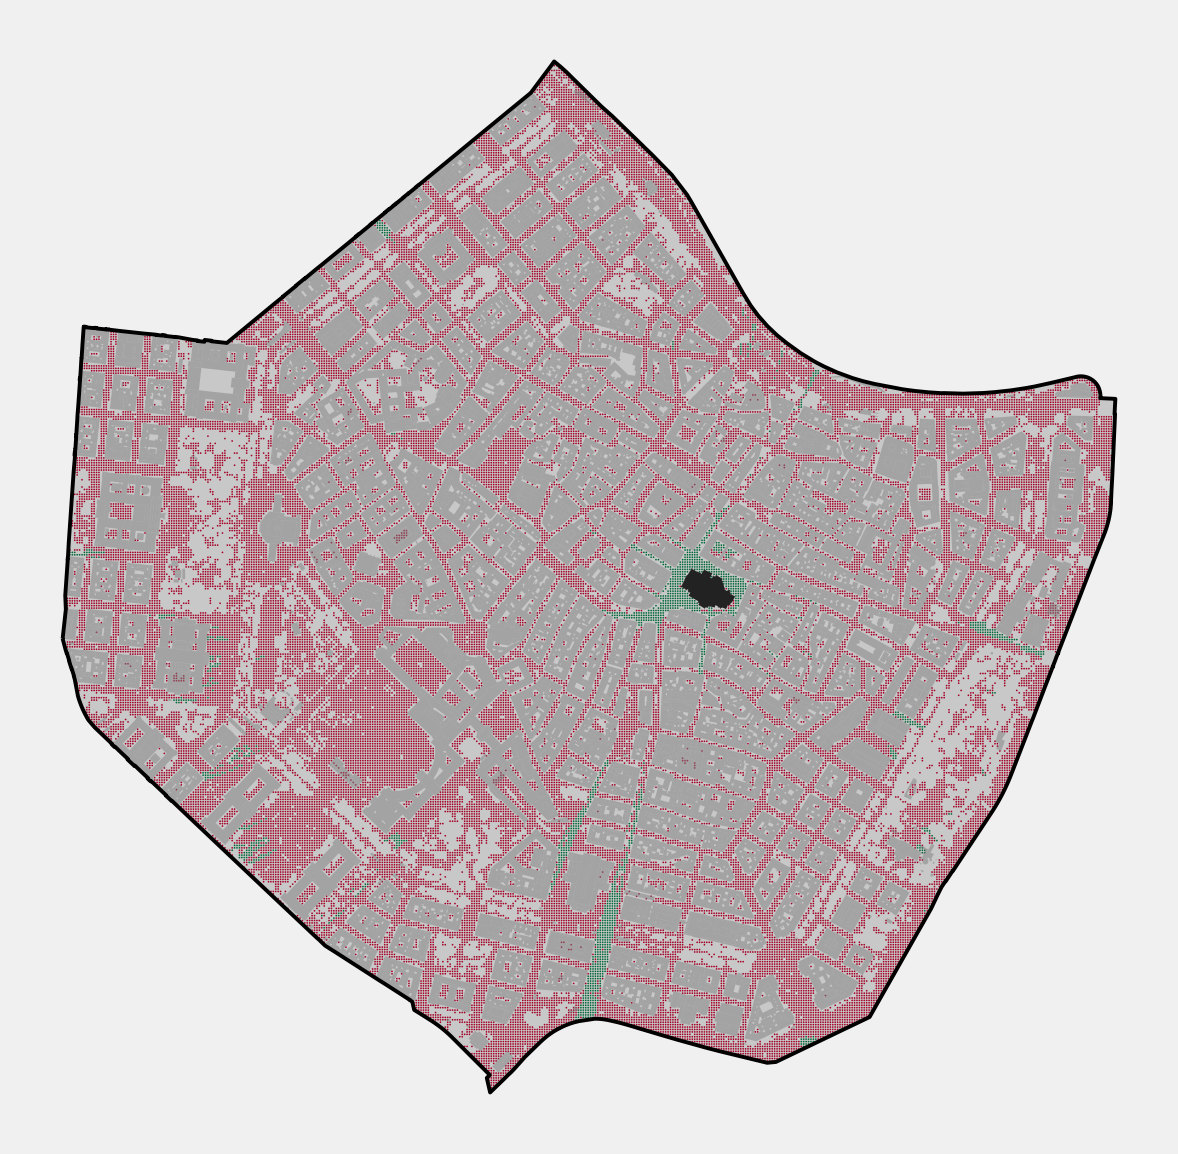

In [4]:
fig, ax = plt.subplots(figsize=(12, 12))

district.plot(
    ax=ax,
    color="#c8c8c8",
)

district.boundary.plot(
    ax=ax,
    color="black",
    linewidth=2.8
)

gdf.plot(
    ax=ax,
    column="visible",
    categorical=True,
    cmap="RdYlGn",
    markersize=1.5,
    legend=False,
    edgecolor="none",
)

gdf_buildings.plot(
    ax=ax,
    color="grey",
    alpha=0.5
)

dom.plot(
    ax=ax,
    color="#222222"
)

ax.set_aspect("equal")
ax.axis("off")

plt.tight_layout()
plt.savefig("maps/map05.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

In [4]:
print(gdf["visible"].value_counts())

visible
0    42585
1     1742
Name: count, dtype: int64
